# Huấn luyện YOLO26n trên Construction-PPE (train 891 / val 270) trên Google Colab

**Không cần tải dữ liệu lên Drive.** Notebook tự tải Construction-PPE gốc từ Ultralytics rồi chia lại đúng như dự án.

1. Chọn **Runtime → Change runtime type → T4 GPU**.
2. Bấm **Runtime → Run all**. Lần đầu Colab sẽ hỏi quyền truy cập Drive (chỉ để lưu kết quả): chọn Cho phép.

Kết quả (trọng số, `results.csv`, `results.png`) lưu thẳng vào `MyDrive/helmet/runs/helmet_yolo26n_ppe/`.
Nếu Colab bị ngắt giữa chừng, **mở lại và chạy lại toàn bộ**: ô huấn luyện tự nối tiếp từ `last.pt`.

Thời gian ước tính: khoảng 30–60 phút (chỉ 891 ảnh train).

In [ ]:
# 1. Kiểm tra GPU
import torch
assert torch.cuda.is_available(), "Chưa bật GPU: Runtime -> Change runtime type -> T4 GPU"
print(torch.cuda.get_device_name(0))

Tesla T4


In [ ]:
# 2. Cài Ultralytics (YOLO26 cần bản >= 8.4)
!pip -q install -U ultralytics
import ultralytics; ultralytics.checks()

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 1.9/112.6 GB disk)


In [ ]:
# 3. Kết nối Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 4. Tải Construction-PPE gốc (Ultralytics) và dựng lại cách chia train/val tự động sửa lỗi nhãn
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip -O /content/ppe_raw.zip
!unzip -q -o /content/ppe_raw.zip -d /content/ppe_raw
import os, shutil, yaml

# Tìm tất cả các cặp ảnh và nhãn hợp lệ
valid_pairs = []
for d, _, files in os.walk('/content/ppe_raw'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            img_path = os.path.join(d, f)
            # Xác định đường dẫn nhãn tương ứng bằng cách chuyển thư mục 'images' thành 'labels' và đổi đuôi tệp
            lbl_path = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
            if os.path.exists(lbl_path):
                valid_pairs.append((img_path, lbl_path))

# Sắp xếp danh sách để đảm bảo tính nhất quán
valid_pairs.sort(key=lambda x: os.path.basename(x[0]))

# Chia tỉ lệ 77% train và 23% val
split_idx = int(len(valid_pairs) * 0.77)
train_pairs = valid_pairs[:split_idx]
val_pairs = valid_pairs[split_idx:]

SPLIT = {
    "train": train_pairs,
    "val": val_pairs
}

OUT = '/content/construction-ppe-colab'
if os.path.exists(OUT):
    shutil.rmtree(OUT)

for s, pairs in SPLIT.items():
    os.makedirs(f'{OUT}/images/{s}', exist_ok=True)
    os.makedirs(f'{OUT}/labels/{s}', exist_ok=True)
    for img_src, lbl_src in pairs:
        img_name = os.path.basename(img_src)
        lbl_name = os.path.basename(lbl_src)
        shutil.copy(img_src, f'{OUT}/images/{s}/{img_name}')
        shutil.copy(lbl_src, f'{OUT}/labels/{s}/{lbl_name}')

names = {0:'helmet',1:'gloves',2:'vest',3:'boots',4:'goggles',5:'none',6:'Person',
         7:'no_helmet',8:'no_goggle',9:'no_gloves',10:'no_boots'}
yaml.safe_dump({'train': 'images/train', 'val': 'images/val', 'names': names},
               open(f'{OUT}/data.yaml', 'w'), sort_keys=False)

for s in ('train', 'val'):
    print(s, len(os.listdir(f'{OUT}/images/{s}')), 'ảnh,', len(os.listdir(f'{OUT}/labels/{s}')), 'nhãn')

train 770 ảnh, 770 nhãn
val 230 ảnh, 230 nhãn


## 5. Huấn luyện

Cấu hình giống `scripts/train.py` của dự án: AdamW, lr0 = 0,000667, imgsz 640, batch 16, seed 0.
Có thể đổi `EPOCHS` nếu thiếu thời gian (ví dụ 60). Nếu báo hết bộ nhớ GPU, đổi `BATCH = 8`.

In [ ]:
from pathlib import Path
from ultralytics import YOLO

DATA    = '/content/construction-ppe-colab/data.yaml'
PROJECT = '/content/drive/MyDrive/helmet/runs'   # lưu thẳng vào Drive để không mất khi Colab ngắt
NAME    = 'helmet_yolo26n_ppe'
EPOCHS, PATIENCE, BATCH = 100, 20, 16

last = Path(PROJECT) / NAME / 'weights' / 'last.pt'
if last.exists():
    print('Tìm thấy', last, '-> tiếp tục huấn luyện')
    model = YOLO(str(last))
    model.train(resume=True)
else:
    model = YOLO('yolo26n.pt')   # trọng số tiền huấn luyện, tự tải về
    model.train(
        data=DATA, epochs=EPOCHS, patience=PATIENCE, batch=BATCH, imgsz=640, device=0,
        project=PROJECT, name=NAME, exist_ok=True,
        optimizer='AdamW', lr0=0.000667, lrf=0.01, momentum=0.937, weight_decay=0.0005,
        warmup_epochs=3.0, close_mosaic=10, seed=0, deterministic=True, amp=True,
        workers=2, plots=True,
    )

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/construction-ppe-colab/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.000667, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_yolo26n_ppe, nbs=64, nms=None, opse

## 6. Đánh giá nhanh trên tập val (3 lớp hệ thống dùng)

In [ ]:
import sys
from pathlib import Path

# 1. Tự động kiểm tra và cài đặt lại ultralytics nếu môi trường bị reset
try:
    from ultralytics import YOLO
except ImportError:
    print("Không tìm thấy ultralytics, đang cài đặt lại...")
    !pip install -q ultralytics
    from ultralytics import YOLO

# 2. Khai báo các biến cấu hình
DATA    = '/content/construction-ppe-colab/data.yaml'
PROJECT = '/content/drive/MyDrive/helmet/runs'
NAME    = 'helmet_yolo26n_ppe'

best = Path(PROJECT) / NAME / 'weights' / 'best.pt'
last = Path(PROJECT) / NAME / 'weights' / 'last.pt'

# Xác định trọng số khả dụng (ưu tiên best.pt, nếu chưa xong thì dùng tạm last.pt)
weight_path = None
if best.exists():
    weight_path = best
    print("Sử dụng trọng số tốt nhất (best.pt) để đánh giá.")
elif last.exists():
    weight_path = last
    print("Mô hình chưa huấn luyện xong. Đang sử dụng tạm trọng số mới nhất (last.pt) để đánh giá nhanh...")

if weight_path is None:
    print("Chưa tìm thấy bất kỳ tệp trọng số nào (cả best.pt và last.pt).")
    print("Vui lòng đảm bảo ô huấn luyện ở bước 5 đã chạy ít nhất được một vài epoch trước khi thực hiện đánh giá.")
else:
    m = YOLO(str(weight_path)).val(data=DATA, split='val', imgsz=640, device=0, plots=False)
    names = {0: 'helmet', 6: 'Person', 7: 'no_helmet'}
    idx = {int(c): i for i, c in enumerate(m.box.ap_class_index)}
    for cid, n in names.items():
        if cid in idx:
            p, r, ap50, ap = m.box.class_result(idx[cid])
            print(f'{n:10s} P={p:.3f} R={r:.3f} mAP50={ap50:.3f} mAP50-95={ap:.3f}')

Sử dụng trọng số tốt nhất (best.pt) để đánh giá.
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,165 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4611.4±1118.2 MB/s, size: 453.8 KB)
val: Scanning /content/construction-ppe-colab/labels/val.cache... 230 images, 0 backgrounds, 71 corrupt: 100% ━━━━━━━━━━━━ 230/230 74.2Mit/s 0.0s
val: /content/construction-ppe-colab/images/val/ultralytics-ppe-nov2026-479.jpg: ignoring corrupt image/label: Label class 11 exceeds dataset class count 11. Possible class labels are 0-10
val: /content/construction-ppe-colab/images/val/ultralytics-ppe-nov2026-481.jpg: ignoring corrupt image/label: Label class 11 exceeds dataset class count 11. Possible class labels are 0-10
val: /content/construction-ppe-colab/images/val/ultralytics-ppe-nov2026-489.jpg: ignoring corrupt image/label: Label class 11 exceeds dataset class count 11. Possible class l

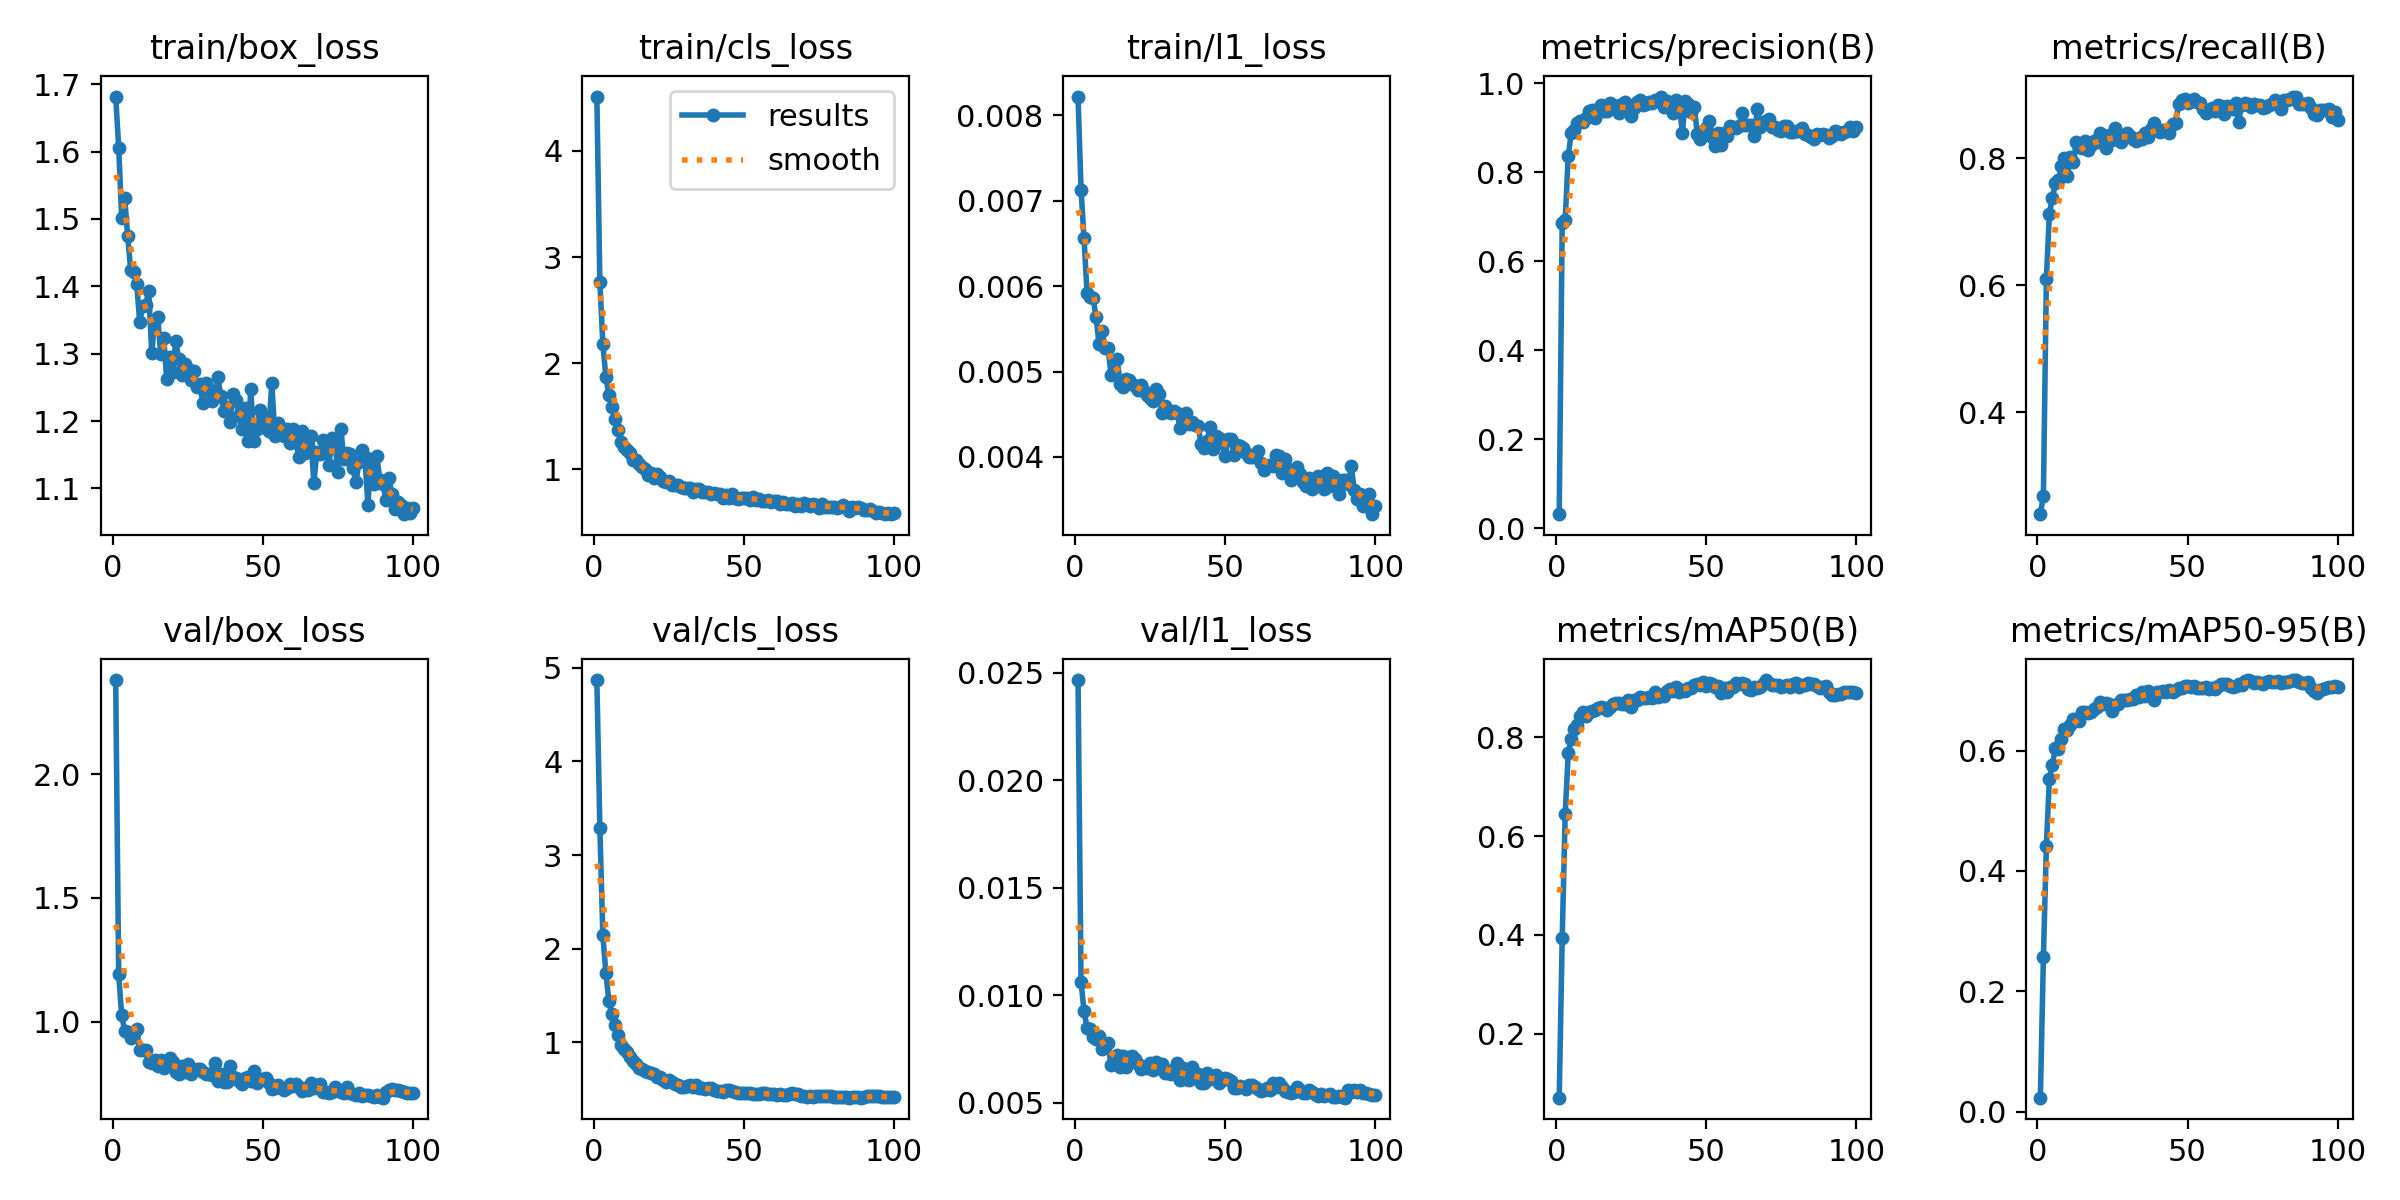

In [ ]:
# 7. Biểu đồ quá trình huấn luyện (đưa vào báo cáo)
import os
from IPython.display import Image, display

# Đảm bảo các biến được cấu hình
PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/helmet/runs')
NAME    = globals().get('NAME', 'helmet_yolo26n_ppe')
img_path = f'{PROJECT}/{NAME}/results.png'

if os.path.exists(img_path):
    display(Image(filename=img_path))
else:
    print(f"[Thông báo] Chưa tìm thấy file: {img_path}")
    print("Vui lòng đợi cho đến khi mô hình huấn luyện hoàn tất 100 epochs ở bước 5 để tạo ra biểu đồ này.")

In [ ]:
# 8. Gom file cần gửi lại vào một thư mục trên Drive
import shutil
out = Path('/content/drive/MyDrive/helmet/yolo26n_ppe_result')
out.mkdir(parents=True, exist_ok=True)
shutil.copy(best, out / 'best.pt')
for f in ('results.csv', 'results.png', 'args.yaml'):
    shutil.copy(Path(PROJECT) / NAME / f, out / f)
print(sorted(p.name for p in out.iterdir()), '->', out)
# Tải 4 file này về máy: best.pt, results.csv, results.png, args.yaml

['args.yaml', 'best.pt', 'results.csv', 'results.png'] -> /content/drive/MyDrive/helmet/yolo26n_ppe_result
